# 休眠求職者の再稼働予測デモ（ダミーデータ）
**目的**：データサイエンスで「何ができるか」を、具体的なアウトプットで見せる。

※ すべて架空のダミーデータです。数値は実際の成果を示すものではなく、「こういう形で出せる」というイメージ用です。

**このノートブックが出力するもの（outputs/ フォルダ）**
| ファイル | 中身 | 上司に見せるポイント |
|---|---|---|
| dormant_seekers.csv | ダミーの休眠求職者データ（2万件） | BigQueryにあるデータのイメージ |
| 01_recency_vs_rate.png / recency_table.csv | 最終活動からの日数別の再稼働率 | 「休眠」をデータで定義できる |
| 02_segments.csv / .png | 休眠タイプ別のプロフィール | 一律配信ではなく層ごとに出し分け |
| 03_decile_table.csv / .png | スコア順の再稼働率（デシル表） | 「上位ほど戻る」の証明 |
| 04_gain_curve.png | 累積捕捉率 | 少ない接触で多くを捕まえられる |
| 05_feature_importance.png | 効いている要因 | 勘ではなく根拠で説明 |
| 06_channel_recommendation.png / .csv | 推奨チャネルと試算 | メール・SMS・LINE・電話の使い分け |
| 07_business_simulation.csv / .png | 配信絞り込みの費用対効果 | CPA・ROIの言葉で語れる |
| call_priority_list.csv | 優先架電リスト（上位300） | 現場がすぐ使える形 |
| suppress_candidates.csv | 配信頻度削減候補 | 配信コスト削減 |

In [24]:
!apt-get -y install fonts-noto-cjk
!rm -rf /root/.cache/matplotlib

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto-cjk is already the newest version (1:20230817+repack1-3).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [25]:
!pip install japanize-matplotlib
import matplotlib.pyplot as plt
import japanize_matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 40.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for japanize-matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120306 sha256=be638b65f7898692fed0f3f2b82682e1a21ec5a1716f791f597aced0a9bd262e
  Stored in directory: /root/.cache/pip/wheels/56/8b/41/7c8a47025c6eef46f0b7488f2510fff13e48f1e7d5bf26e21b
Successfully built japanize-matplotlib


In [26]:
# ===== 0. 準備 =====
import os
import shutil
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

SEED = 42
N = 20000
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)


def setup_japanese_font():
    """日本語フォントを設定する（Colab/Codespacesでは必要に応じて自動インストール）。"""
    def find():
        keys = ["Noto Sans CJK JP", "IPAexGothic", "IPAGothic", "Hiragino",
                "Yu Gothic", "Meiryo", "TakaoGothic", "Noto Sans JP"]
        names = {f.name for f in font_manager.fontManager.ttflist}
        for k in keys:
            for n in names:
                if k.lower() in n.lower():
                    return n
        return None

    name = find()
    if name is None:
        try:
            subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-noto-cjk"],
                           check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            font_manager.fontManager = font_manager._load_fontmanager(try_read_cache=False)
            name = find()
        except Exception:
            pass
    if name:
        plt.rcParams["font.family"] = name
    else:
        print("日本語フォントが見つかりません。グラフの日本語が文字化けする場合は、"
              "'apt-get install fonts-noto-cjk' 後にランタイムを再起動してください。")
    plt.rcParams["axes.unicode_minus"] = False


setup_japanese_font()
plt.rcParams["figure.dpi"] = 110

CHANNELS = ["email", "sms", "line", "call"]
CHANNEL_JP = {"email": "メール", "sms": "SMS", "line": "LINE", "call": "電話"}
# 1接触あたりのコスト（円）。電話は工数換算。ダミーの仮置き
COST = {"email": 1, "sms": 8, "line": 2, "call": 600}

## 1. ダミーデータの生成
実データのイメージ（BigQuery上のCRM・Salesforce・サイト行動・配信履歴）に合わせた列を作ります。
- 「休眠」＝最終活動から90日以上
- 過去の再稼働キャンペーンで、各人に1つのチャネル（メール/SMS/LINE/電話）で接触した、という設定
- 目的変数 `reactivated_30d`：接触後30日以内に面談・通話が成立したか

In [27]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def calibrate_intercept(z, target_rate):
    """平均再稼働率が target_rate になるように切片を調整する。"""
    lo, hi = -15.0, 15.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if sigmoid(z + mid).mean() > target_rate:
            hi = mid
        else:
            lo = mid
    return (lo + hi) / 2


def make_dummy_data(n=N, seed=SEED, target_rate=0.08):
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({"seeker_id": [f"S{i:06d}" for i in range(1, n + 1)]})

    # --- 基準日（過去3回のキャンペーン時点のスナップショット） ---
    snap = rng.choice(["2025-04-01", "2025-07-01", "2025-10-01"], n)
    df["snapshot_date"] = pd.to_datetime(snap)
    month = df["snapshot_date"].dt.month.to_numpy()

    # --- 属性 ---
    job_types = ["看護師", "薬剤師", "理学療法士", "介護福祉士", "歯科衛生士", "医療事務", "医師"]
    df["job_type"] = rng.choice(job_types, n, p=[0.34, 0.14, 0.08, 0.18, 0.08, 0.14, 0.04])
    df["age"] = np.clip(rng.normal(34, 8, n), 21, 64).round().astype(int)
    df["years_experience"] = np.clip(df["age"] - 22 - rng.integers(0, 6, n), 0, 40)
    df["area"] = rng.choice(["東京", "神奈川・埼玉・千葉", "大阪・関西", "愛知", "福岡", "その他"], n,
                            p=[0.18, 0.22, 0.17, 0.08, 0.06, 0.29])
    df["registration_channel"] = rng.choice(
        ["広告_検索", "広告_SNS", "オウンドメディア", "紹介", "求人サイト経由"], n,
        p=[0.30, 0.22, 0.20, 0.10, 0.18])
    df["currently_employed"] = (rng.random(n) < 0.80).astype(int)
    df["preferred_time_band"] = rng.choice(["平日昼", "平日夜", "休日"], n, p=[0.30, 0.45, 0.25])

    # --- 休眠の長さ ---
    intent = rng.normal(0, 1, n)  # 目に見えない「転職意欲」（出力CSVには含めない）
    last_act = np.minimum(rng.gamma(2.0, 110, n) + 90, 720).round().astype(int)
    df["days_since_last_activity"] = last_act
    df["days_since_registration"] = last_act + rng.integers(0, 900, n)

    # --- 過去の面談・応募 ---
    interviews = np.clip(rng.poisson(0.8 * np.exp(0.2 * intent)), 0, 5)
    df["past_interview_count"] = interviews
    df["past_application_count"] = np.clip(rng.poisson(interviews * 0.8 + 0.3), 0, 8)

    # --- サイト・メディア行動（直近90日） ---
    lam = 3 * np.exp(-0.5 + 0.5 * intent - last_act / 300)
    df["site_visits_90d"] = np.clip(rng.poisson(lam), 0, 30)
    df["job_views_90d"] = np.clip(rng.poisson(lam * 4), 0, 80)
    media_boost = np.where(df["registration_channel"] == "オウンドメディア", 1.8, 1.0)
    df["media_article_views_90d"] = np.clip(rng.poisson(1.2 * np.exp(0.2 * intent) * media_boost), 0, 30)

    # --- 配信・架電（全体配信の想定） ---
    df["email_sent_90d"] = rng.integers(6, 40, n)
    open_rate = np.clip(rng.beta(2, 6, n) + 0.04 * intent, 0, 1)
    df["email_open_rate_90d"] = open_rate.round(3)
    df["sms_sent_90d"] = rng.integers(0, 8, n)
    line_friend = rng.random(n) < 0.45
    df["line_friend"] = line_friend.astype(int)
    line_read = np.where(line_friend, np.clip(rng.beta(3, 3, n) + 0.05 * intent, 0, 1), 0.0)
    df["line_read_rate"] = line_read.round(3)
    attempts = rng.integers(0, 12, n)
    df["call_attempts_90d"] = attempts
    connect = np.clip(rng.beta(1.5, 6, n) + 0.03 * intent, 0, 1)
    connect = np.where(attempts > 0, connect, 0.0)
    df["call_connect_rate"] = connect.round(3)

    # --- 同意・配信可否 ---
    opt_out = rng.random(n) < 0.07
    consent_sms = rng.random(n) < 0.80
    df["opt_out_email"] = opt_out.astype(int)
    df["consent_sms"] = consent_sms.astype(int)

    # --- 過去キャンペーンで使ったチャネル（配信可能なものからランダムに割当） ---
    allowed = np.column_stack([~opt_out, consent_sms, line_friend, np.ones(n, dtype=bool)])
    r = rng.random((n, 4)) * allowed
    ch = np.array(CHANNELS)[r.argmax(axis=1)]
    df["contact_channel"] = ch

    # --- 再稼働（接触後30日以内に面談・通話が成立）の確率 ---
    age = df["age"].to_numpy()
    job_eff = df["job_type"].map({"看護師": 0.2, "薬剤師": 0.0, "理学療法士": 0.1, "介護福祉士": 0.1,
                                  "歯科衛生士": -0.1, "医療事務": -0.3, "医師": 0.3}).to_numpy()
    season = np.select([month == 4, month == 10, month == 7], [0.3, 0.2, -0.1], default=0.0)
    channel_effect = np.select(
        [ch == "email", ch == "sms", ch == "line", ch == "call"],
        [-0.2 + 2.5 * (open_rate - 0.2),
         -0.1 + 0.4 * (age < 30) - 0.2 * (age >= 40),
         0.1 + 2.0 * line_read,
         0.2 + 3.0 * (connect - 0.2)])
    z = (0.9 * intent
         - 0.0035 * (last_act - 200)
         + 0.6 * np.log1p(df["site_visits_90d"].to_numpy())
         + 0.35 * interviews
         + 0.7 * (1 - df["currently_employed"].to_numpy())
         + 0.3 * (age < 30)
         + job_eff + season + channel_effect
         + rng.normal(0, 0.3, n))
    z = z + calibrate_intercept(z, target_rate)
    df["reactivated_30d"] = (rng.random(n) < sigmoid(z)).astype(int)
    return df


df = make_dummy_data()
df.to_csv(f"{OUT}/dormant_seekers.csv", index=False, encoding="utf-8-sig")
print(f"件数: {len(df):,} / 再稼働率（全体）: {df['reactivated_30d'].mean():.1%}")
df.head()

件数: 20,000 / 再稼働率（全体）: 8.0%


,seeker_id,snapshot_date,job_type,age,years_experience,area,registration_channel,currently_employed,preferred_time_band,days_since_last_activity,...,email_open_rate_90d,sms_sent_90d,line_friend,line_read_rate,call_attempts_90d,call_connect_rate,opt_out_email,consent_sms,contact_channel,reactivated_30d
0,S000001,2025-04-01,介護福祉士,21,0,愛知,広告_検索,1,平日夜,142,...,0.141,6,1,0.642,4,0.363,0,1,email,0
1,S000002,2025-10-01,介護福祉士,27,0,大阪・関西,紹介,1,平日夜,171,...,0.145,2,1,0.261,0,0.000,0,0,email,0
2,S000003,2025-07-01,看護師,26,3,その他,オウンドメディア,1,平日夜,230,...,0.383,1,1,0.442,8,0.100,0,1,line,0
3,S000004,2025-07-01,看護師,29,5,神奈川・埼玉・千葉,広告_検索,1,平日夜,196,...,0.126,7,1,0.536,1,0.170,0,1,sms,0
4,S000005,2025-07-01,看護師,36,13,東京,広告_検索,1,平日昼,93,...,0.437,6,1,0.639,0,0.000,0,1,email,0


## 2. 「休眠」をデータで定義する
最終活動からの日数ごとに再稼働率を見て、区分の境目を決めます。（実データでも同じ手順）

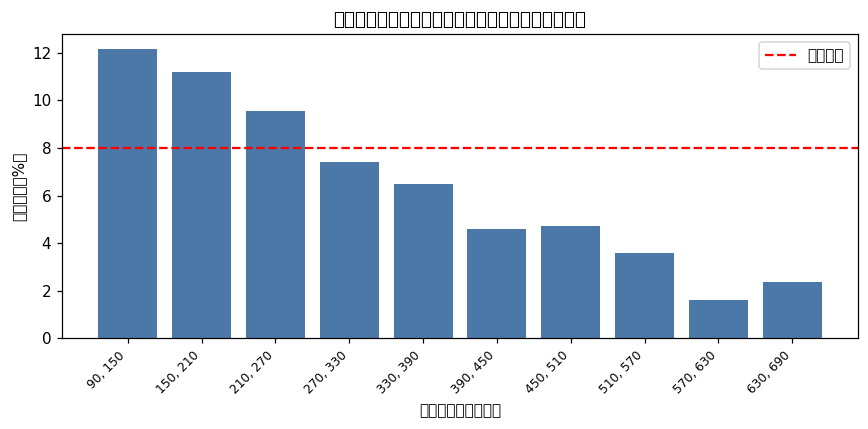

                  人数      再稼働率
dormant_stage                 
準休眠(3-6か月)      3859  0.121534
休眠(6-12か月)     10321  0.085457
深い休眠(12か月〜)     5820  0.042784


In [28]:
bins = list(range(90, 750, 60))
df["recency_bin"] = pd.cut(df["days_since_last_activity"], bins=bins, right=False)
recency = (df.groupby("recency_bin", observed=True)["reactivated_30d"]
             .agg(人数="size", 再稼働人数="sum", 再稼働率="mean").reset_index())
recency["recency_bin"] = recency["recency_bin"].astype(str)
recency.to_csv(f"{OUT}/recency_table.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(recency)), recency["再稼働率"] * 100, color="#4C78A8")
ax.set_xticks(range(len(recency)))
ax.set_xticklabels(recency["recency_bin"].str.replace("[", "", regex=False).str.replace(")", "", regex=False),
                   rotation=45, ha="right", fontsize=8)
ax.axhline(df["reactivated_30d"].mean() * 100, color="red", ls="--", label="全体平均")
ax.set_ylabel("再稼働率（%）")
ax.set_xlabel("最終活動からの日数")
ax.set_title("最終活動からの日数別の再稼働率（ダミーデータ）")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/01_recency_vs_rate.png")
plt.show()

df["dormant_stage"] = pd.cut(df["days_since_last_activity"], [0, 180, 365, np.inf],
                             labels=["準休眠(3-6か月)", "休眠(6-12か月)", "深い休眠(12か月〜)"], right=False)
print(df.groupby("dormant_stage", observed=True)["reactivated_30d"].agg(["size", "mean"]).rename(
    columns={"size": "人数", "mean": "再稼働率"}))

## 3. 休眠タイプの分類（クラスタリング）
行動パターンが似ている人を自動でグループ分けし、層ごとの特徴と再稼働率を出します。

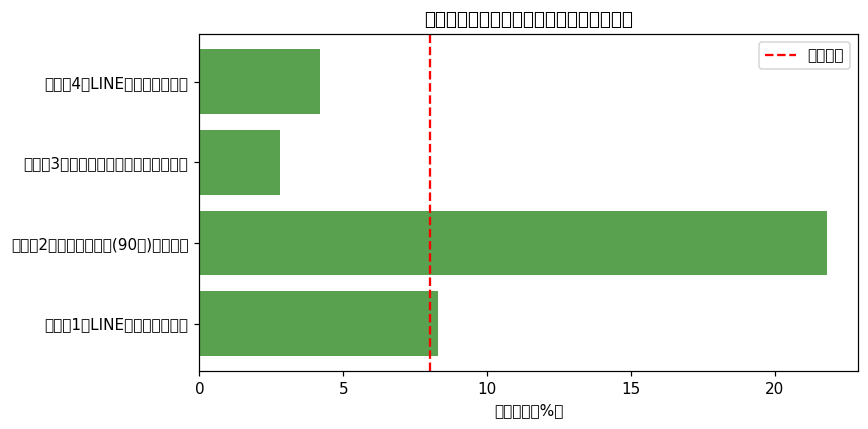

,人数,再稼働率,最終活動からの日数,サイト訪問数(90日),求人閲覧数(90日),記事閲覧数(90日),メール開封率,LINE既読率,電話接続率,過去の面談数,年齢
タイプ1：LINE既読率が高い層,5240,0.083,275.22,0.66,3.05,1.33,0.25,0.58,0.18,0.77,34.12
タイプ2：サイト訪問数(90日)が高い層,3423,0.218,212.75,2.25,7.13,2.00,0.32,0.19,0.23,1.16,34.17
タイプ3：最終活動からの日数が高い層,4044,0.028,532.41,0.28,1.18,1.52,0.26,0.16,0.18,0.85,34.24
タイプ4：LINE既読率が低い層,7293,0.042,252.68,0.54,2.72,1.13,0.22,0.03,0.16,0.68,33.91


In [29]:
FEATURE_JP = {
    "age": "年齢", "years_experience": "経験年数", "days_since_registration": "登録からの日数",
    "days_since_last_activity": "最終活動からの日数", "past_interview_count": "過去の面談数",
    "past_application_count": "過去の応募数", "site_visits_90d": "サイト訪問数(90日)",
    "job_views_90d": "求人閲覧数(90日)", "media_article_views_90d": "記事閲覧数(90日)",
    "email_sent_90d": "メール送信数(90日)", "email_open_rate_90d": "メール開封率",
    "sms_sent_90d": "SMS送信数(90日)", "line_friend": "LINE友だち", "line_read_rate": "LINE既読率",
    "call_attempts_90d": "架電回数(90日)", "call_connect_rate": "電話接続率",
    "opt_out_email": "メール配信停止", "consent_sms": "SMS同意", "currently_employed": "在職中",
    "snapshot_month": "接触月", "job_type": "職種", "area": "エリア",
    "registration_channel": "登録経路", "contact_channel": "接触チャネル",
    "preferred_time_band": "希望時間帯",
}

SEG_COLS = ["days_since_last_activity", "site_visits_90d", "job_views_90d", "media_article_views_90d",
            "email_open_rate_90d", "line_read_rate", "call_connect_rate", "past_interview_count", "age"]

Xs = StandardScaler().fit_transform(df[SEG_COLS])
df["segment"] = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(Xs)

overall_mean, overall_std = df[SEG_COLS].mean(), df[SEG_COLS].std()
profile = df.groupby("segment")[SEG_COLS].mean()
z = (profile - overall_mean) / overall_std
names = {}
for seg in profile.index:
    col = z.loc[seg].abs().idxmax()
    names[seg] = f"タイプ{seg + 1}：{FEATURE_JP[col]}が{'高い' if z.loc[seg, col] > 0 else '低い'}層"

seg_table = profile.round(2).rename(columns=FEATURE_JP)
seg_table.insert(0, "再稼働率", df.groupby("segment")["reactivated_30d"].mean().round(3))
seg_table.insert(0, "人数", df.groupby("segment").size())
seg_table.index = [names[i] for i in seg_table.index]
seg_table.to_csv(f"{OUT}/02_segments.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(seg_table.index, seg_table["再稼働率"] * 100, color="#59A14F")
ax.axvline(df["reactivated_30d"].mean() * 100, color="red", ls="--", label="全体平均")
ax.set_xlabel("再稼働率（%）")
ax.set_title("休眠タイプ別の再稼働率（ダミーデータ）")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/02_segments.png")
plt.show()
seg_table

## 4. 再稼働予測モデル
- 過去2回（4月・7月）のデータで学習し、直近（10月）で検証（時間で分割＝未来を見ない）
- ベースライン：ロジスティック回帰 / 本命：勾配ブースティング

In [30]:
df["snapshot_month"] = df["snapshot_date"].dt.month

NUM_COLS = ["age", "years_experience", "days_since_registration", "days_since_last_activity",
            "past_interview_count", "past_application_count", "site_visits_90d", "job_views_90d",
            "media_article_views_90d", "email_sent_90d", "email_open_rate_90d", "sms_sent_90d",
            "line_friend", "line_read_rate", "call_attempts_90d", "call_connect_rate",
            "opt_out_email", "consent_sms", "currently_employed", "snapshot_month"]
CAT_COLS = ["job_type", "area", "registration_channel", "contact_channel", "preferred_time_band"]
FEATURES = NUM_COLS + CAT_COLS
TARGET = "reactivated_30d"

train = df[df["snapshot_date"] < "2025-10-01"]
test = df[df["snapshot_date"] == "2025-10-01"].copy()
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]


def make_pipe(model, scale=False):
    num = StandardScaler() if scale else "passthrough"
    pre = ColumnTransformer([
        ("num", num, NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])
    return Pipeline([("pre", pre), ("model", model)])


base_pipe = make_pipe(LogisticRegression(max_iter=1000), scale=True).fit(X_train, y_train)
gb_pipe = make_pipe(HistGradientBoostingClassifier(
    max_depth=4, learning_rate=0.05, max_iter=300, random_state=SEED)).fit(X_train, y_train)

result = []
for name, pipe in [("ロジスティック回帰（ベースライン）", base_pipe), ("勾配ブースティング", gb_pipe)]:
    p = pipe.predict_proba(X_test)[:, 1]
    result.append({"モデル": name, "ROC-AUC": roc_auc_score(y_test, p),
                   "PR-AUC": average_precision_score(y_test, p)})
print(f"検証データの再稼働率（無作為に選んだ場合のPR-AUCの目安）: {y_test.mean():.3f}")
pd.DataFrame(result).round(3)

検証データの再稼働率（無作為に選んだ場合のPR-AUCの目安）: 0.084


,モデル,ROC-AUC,PR-AUC
0,ロジスティック回帰（ベースライン）,0.791,0.329
1,勾配ブースティング,0.786,0.308


## 5. アウトプット①：スコア順の再稼働率（デシル表）と累積捕捉率
「スコア上位ほど本当に戻っているか」を見せる、最も伝わりやすい図です。

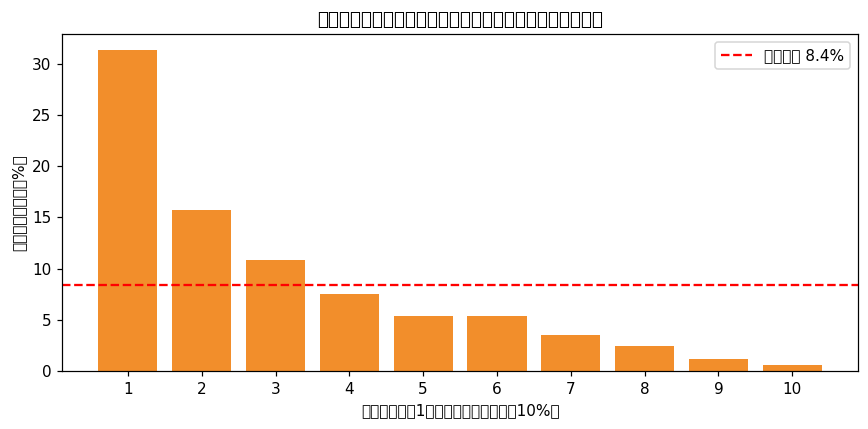

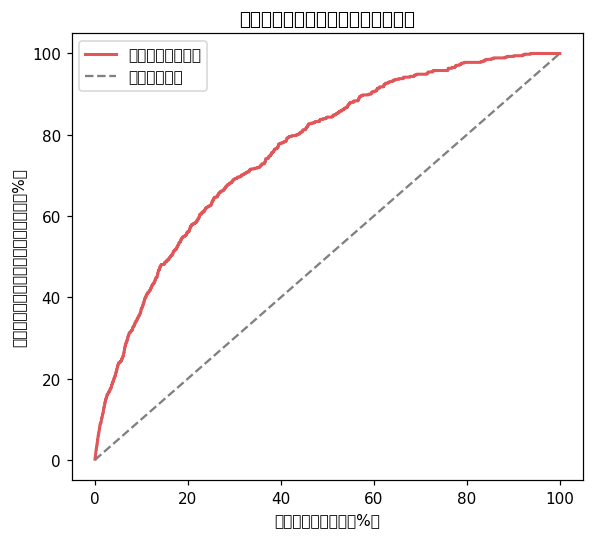

上位10%に接触 → 再稼働者の 37% を捕捉
上位20%に接触 → 再稼働者の 56% を捕捉
上位30%に接触 → 再稼働者の 69% を捕捉
上位50%に接触 → 再稼働者の 84% を捕捉


,decile,人数,再稼働人数,再稼働率,リフト（全体平均比）
0,1,655,205,0.313,3.733
1,2,655,103,0.157,1.876
2,3,655,71,0.108,1.293
3,4,654,49,0.075,0.894
4,5,655,35,0.053,0.637
5,6,655,35,0.053,0.637
6,7,654,23,0.035,0.419
7,8,655,16,0.024,0.291
8,9,655,8,0.012,0.146
9,10,655,4,0.006,0.073


In [31]:
test["score_actual"] = gb_pipe.predict_proba(X_test)[:, 1]  # 実際に接触したチャネルでの再稼働確率
rank = test["score_actual"].rank(method="first", ascending=False)
test["decile"] = pd.qcut(rank, 10, labels=range(1, 11)).astype(int)

overall_rate = test[TARGET].mean()
decile = (test.groupby("decile")[TARGET].agg(人数="size", 再稼働人数="sum", 再稼働率="mean").reset_index())
decile["リフト（全体平均比）"] = decile["再稼働率"] / overall_rate
decile.round(3).to_csv(f"{OUT}/03_decile_table.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(decile["decile"], decile["再稼働率"] * 100, color="#F28E2B")
ax.axhline(overall_rate * 100, color="red", ls="--", label=f"全体平均 {overall_rate:.1%}")
ax.set_xticks(range(1, 11))
ax.set_xlabel("スコア順位（1＝最も戻りやすい上位10%）")
ax.set_ylabel("実際の再稼働率（%）")
ax.set_title("スコア上位ほど実際に戻っている（検証データ・ダミー）")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/03_decile_chart.png")
plt.show()

# 累積捕捉率
ordered = test.sort_values("score_actual", ascending=False)
frac = np.arange(1, len(ordered) + 1) / len(ordered)
capture = ordered[TARGET].cumsum().to_numpy() / ordered[TARGET].sum()

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(frac * 100, capture * 100, label="モデルの順に接触", color="#E15759", lw=2)
ax.plot([0, 100], [0, 100], "--", color="gray", label="無作為に接触")
ax.set_xlabel("接触した人の割合（%）")
ax.set_ylabel("再稼働した人のうち捕捉できた割合（%）")
ax.set_title("少ない接触で多くの再稼働を捉える")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/04_gain_curve.png")
plt.show()

for k in [0.1, 0.2, 0.3, 0.5]:
    idx = int(len(ordered) * k) - 1
    print(f"上位{int(k * 100)}%に接触 → 再稼働者の {capture[idx]:.0%} を捕捉")
decile.round(3)

## 6. アウトプット②：効いている要因（なぜそのスコアか）
「どの情報を入れ替えると予測が悪化するか」で重要度を出します。説明材料として使えます。

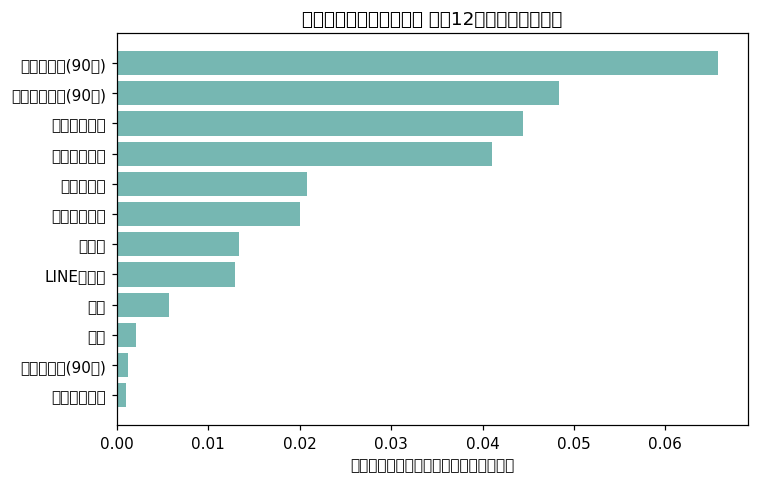

,項目,importance
7,求人閲覧数(90日),0.0657
6,サイト訪問数(90日),0.0483
23,接触チャネル,0.0444
4,過去の面談数,0.0411
15,電話接続率,0.0208
10,メール開封率,0.0200
18,在職中,0.0134
13,LINE既読率,0.0130
0,年齢,0.0057
20,職種,0.0021


In [32]:
imp = permutation_importance(gb_pipe, X_test, y_test, scoring="average_precision",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
imp_df = (pd.DataFrame({"feature": FEATURES, "importance": imp.importances_mean})
          .sort_values("importance", ascending=False).head(12))
imp_df["項目"] = imp_df["feature"].map(FEATURE_JP)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp_df["項目"][::-1], imp_df["importance"][::-1], color="#76B7B2")
ax.set_xlabel("重要度（入れ替えたときの精度の低下）")
ax.set_title("再稼働に効いている要因 上位12（ダミーデータ）")
plt.tight_layout()
plt.savefig(f"{OUT}/05_feature_importance.png")
plt.show()
imp_df[["項目", "importance"]].round(4)

## 7. アウトプット③：チャネル別の推奨（メール・SMS・LINE・電話）
同じ人に4つのチャネルで接触した場合の再稼働確率を予測し、配信可能なチャネルの中から最も高いものを推奨します。
※ 過去のチャネルをランダムに割り当てたダミーデータだからできる試算です。実データでは過去の割当に偏りがないか確認が必要です。

現状（チャネルがバラバラ）の期待再稼働率: 7.3%
推奨チャネルで接触した場合の期待再稼働率: 10.0%  （+37%）


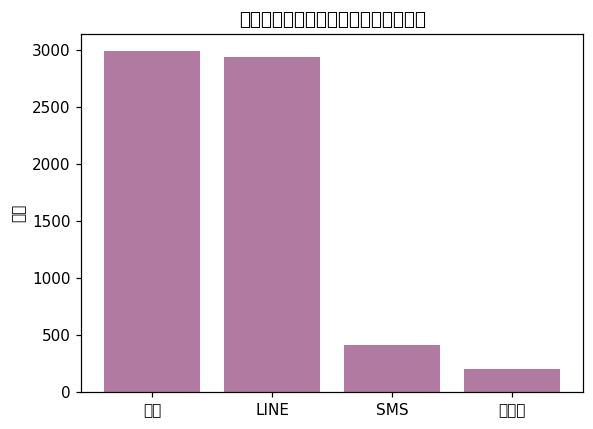

,推奨チャネル,人数,期待再稼働率
0,電話,2991,0.067
1,LINE,2939,0.145
2,SMS,412,0.023
3,メール,206,0.082


In [33]:
def predict_by_channel(pipe, X):
    out = {}
    for c in CHANNELS:
        Xc = X.copy()
        Xc["contact_channel"] = c
        out[c] = pipe.predict_proba(Xc)[:, 1]
    return pd.DataFrame(out, index=X.index)


probs = predict_by_channel(gb_pipe, X_test)
allowed_mask = pd.DataFrame({
    "email": X_test["opt_out_email"] == 0,
    "sms": X_test["consent_sms"] == 1,
    "line": X_test["line_friend"] == 1,
    "call": True,
}, index=X_test.index)
masked = probs.where(allowed_mask, -1)
test["recommended_channel"] = masked.idxmax(axis=1)
test["score_best"] = masked.max(axis=1)

current = test["score_actual"].mean()
optimized = test["score_best"].mean()
print(f"現状（チャネルがバラバラ）の期待再稼働率: {current:.1%}")
print(f"推奨チャネルで接触した場合の期待再稼働率: {optimized:.1%}  （{optimized / current - 1:+.0%}）")

share = test["recommended_channel"].map(CHANNEL_JP).value_counts()
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(share.index, share.values, color="#B07AA1")
ax.set_ylabel("人数")
ax.set_title("推奨チャネルの内訳（ダミーデータ）")
plt.tight_layout()
plt.savefig(f"{OUT}/06_channel_recommendation.png")
plt.show()

channel_summary = pd.DataFrame({
    "推奨チャネル": share.index,
    "人数": share.values,
    "期待再稼働率": [test.loc[test["recommended_channel"].map(CHANNEL_JP) == c, "score_best"].mean()
                     for c in share.index],
}).round(3)
channel_summary.to_csv(f"{OUT}/06_channel_recommendation.csv", index=False, encoding="utf-8-sig")
channel_summary

## 8. アウトプット④：配信を絞った場合の費用対効果（CPA・ROIの言葉で）
スコア上位だけに接触した場合に、接触数・コスト・再稼働数がどう変わるかを試算します。
コストは1接触あたりの仮置き（メール1円、SMS8円、LINE2円、電話600円＝工数換算）。実データでは実際の単価に置き換えます。

全員に接触：コスト 1,351,099円 / 再稼働 549人 / 1再稼働あたり 2,461円
上位30%に接触：コスト 369,817円（-73%） / 再稼働 379人（69%を捕捉） / 1再稼働あたり 976円


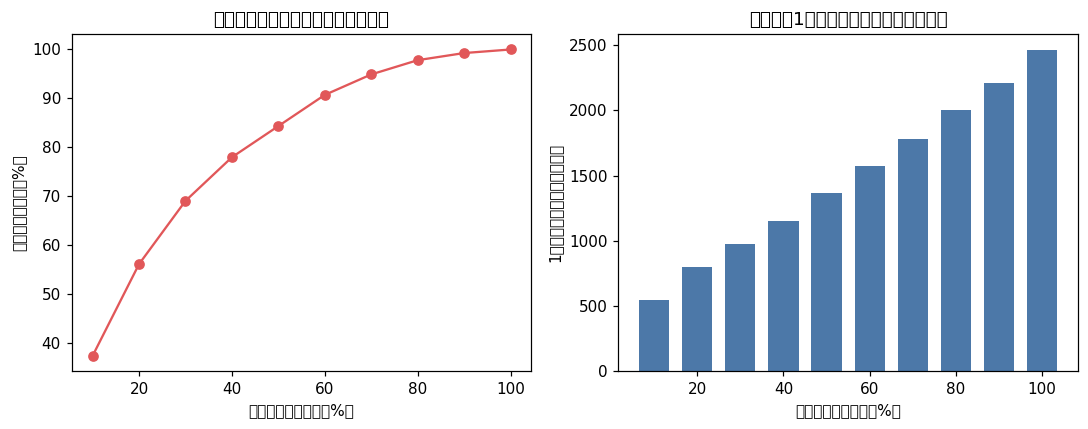

,接触割合,接触数,コスト（円）,再稼働人数,再稼働の捕捉率,1再稼働あたりコスト（円）
0,0.1,654,111202,205,0.373,542.449
1,0.2,1309,245798,308,0.561,798.045
2,0.3,1964,369817,379,0.690,975.770
3,0.4,2619,493950,428,0.780,1154.089
4,0.5,3274,632875,463,0.843,1366.901
5,0.6,3928,783869,498,0.907,1574.034
6,0.7,4583,928377,521,0.949,1781.914
7,0.8,5238,1075828,537,0.978,2003.404
8,0.9,5893,1202469,545,0.993,2206.365
9,1.0,6548,1351099,549,1.000,2461.018


In [34]:
ordered = test.sort_values("score_actual", ascending=False).copy()
ordered["cost"] = ordered["contact_channel"].map(COST)
total_react = ordered[TARGET].sum()

rows = []
for k in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    top = ordered.head(int(len(ordered) * k))
    cost = top["cost"].sum()
    got = top[TARGET].sum()
    rows.append({"接触割合": k, "接触数": len(top), "コスト（円）": cost, "再稼働人数": int(got),
                 "再稼働の捕捉率": got / total_react, "1再稼働あたりコスト（円）": cost / got if got else np.nan})
sim = pd.DataFrame(rows)
sim.round(3).to_csv(f"{OUT}/07_business_simulation.csv", index=False, encoding="utf-8-sig")

all_row = sim[sim["接触割合"] == 1.0].iloc[0]
top30 = sim[sim["接触割合"] == 0.3].iloc[0]
print(f"全員に接触：コスト {all_row['コスト（円）']:,.0f}円 / 再稼働 {int(all_row['再稼働人数'])}人 / "
      f"1再稼働あたり {all_row['1再稼働あたりコスト（円）']:,.0f}円")
print(f"上位30%に接触：コスト {top30['コスト（円）']:,.0f}円（{top30['コスト（円）'] / all_row['コスト（円）'] - 1:+.0%}） / "
      f"再稼働 {int(top30['再稼働人数'])}人（{top30['再稼働の捕捉率']:.0%}を捕捉） / "
      f"1再稼働あたり {top30['1再稼働あたりコスト（円）']:,.0f}円")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(sim["接触割合"] * 100, sim["再稼働の捕捉率"] * 100, marker="o", color="#E15759")
axes[0].set_xlabel("接触した人の割合（%）")
axes[0].set_ylabel("再稼働の捕捉率（%）")
axes[0].set_title("接触を絞っても再稼働の多くを確保")
axes[1].bar(sim["接触割合"] * 100, sim["1再稼働あたりコスト（円）"], width=7, color="#4C78A8")
axes[1].set_xlabel("接触した人の割合（%）")
axes[1].set_ylabel("1再稼働あたりコスト（円）")
axes[1].set_title("絞るほど1再稼働あたりコストが下がる")
plt.tight_layout()
plt.savefig(f"{OUT}/07_business_simulation.png")
plt.show()
sim.round(3)

## 9. アウトプット⑤：現場が使えるリスト
- `call_priority_list.csv`：優先して架電・個別アプローチする上位300名（推奨チャネルと理由つき）
- `suppress_candidates.csv`：配信頻度の削減を検討する下位30%

In [35]:
def reasons(row):
    r = []
    if row["site_visits_90d"] >= 3:
        r.append("直近90日にサイト訪問あり")
    if row["job_views_90d"] >= 8:
        r.append("求人閲覧が多い")
    if row["past_interview_count"] >= 1:
        r.append("過去に面談経験あり")
    if row["days_since_last_activity"] <= 180:
        r.append("最終活動から半年以内")
    if row["currently_employed"] == 0:
        r.append("現在離職中")
    ch = row["recommended_channel"]
    if ch == "email" and row["email_open_rate_90d"] >= 0.3:
        r.append("メール開封率が高い")
    if ch == "line" and row["line_read_rate"] >= 0.5:
        r.append("LINE既読率が高い")
    if ch == "call" and row["call_connect_rate"] >= 0.3:
        r.append("電話がつながりやすい")
    return " / ".join(r[:3]) if r else "－"


final = test.sort_values("score_best", ascending=False).reset_index(drop=True)
final["dormant_stage"] = pd.cut(final["days_since_last_activity"], [0, 180, 365, np.inf],
                                labels=["準休眠(3-6か月)", "休眠(6-12か月)", "深い休眠(12か月〜)"], right=False)

top = final.head(300).copy()
priority = pd.DataFrame({
    "優先順位": np.arange(1, len(top) + 1),
    "求職者ID（ダミー）": top["seeker_id"],
    "再稼働スコア（推奨チャネルで接触した場合）": top["score_best"].round(3),
    "推奨チャネル": top["recommended_channel"].map(CHANNEL_JP),
    "職種": top["job_type"],
    "年齢": top["age"],
    "休眠区分": top["dormant_stage"].astype(str),
    "最終活動からの日数": top["days_since_last_activity"],
    "推奨理由": top.apply(reasons, axis=1),
})
priority.to_csv(f"{OUT}/call_priority_list.csv", index=False, encoding="utf-8-sig")

bottom = final.tail(int(len(final) * 0.3)).copy()
suppress = pd.DataFrame({
    "求職者ID（ダミー）": bottom["seeker_id"],
    "再稼働スコア": bottom["score_best"].round(3),
    "職種": bottom["job_type"],
    "休眠区分": bottom["dormant_stage"].astype(str),
    "最終活動からの日数": bottom["days_since_last_activity"],
    "直近のメール送信数(90日)": bottom["email_sent_90d"],
    "提案": "配信頻度を下げる／低コストチャネルのみにする",
})
suppress.to_csv(f"{OUT}/suppress_candidates.csv", index=False, encoding="utf-8-sig")

print(f"優先リスト: {len(priority)}件 / 配信頻度削減候補: {len(suppress)}件")
priority.head(10)

優先リスト: 300件 / 配信頻度削減候補: 1964件


,優先順位,求職者ID（ダミー）,再稼働スコア（推奨チャネルで接触した場合）,推奨チャネル,職種,年齢,休眠区分,最終活動からの日数,推奨理由
0,1,S017880,0.843,LINE,薬剤師,21,休眠(6-12か月),283,求人閲覧が多い / 過去に面談経験あり / 現在離職中
1,2,S010263,0.813,LINE,看護師,40,休眠(6-12か月),202,直近90日にサイト訪問あり / 求人閲覧が多い / 過去に面談経験あり
2,3,S015832,0.777,LINE,介護福祉士,26,深い休眠(12か月〜),376,直近90日にサイト訪問あり / 過去に面談経験あり / 現在離職中
3,4,S013190,0.744,電話,医師,34,準休眠(3-6か月),133,直近90日にサイト訪問あり / 求人閲覧が多い / 過去に面談経験あり
4,5,S006226,0.739,LINE,薬剤師,43,準休眠(3-6か月),160,直近90日にサイト訪問あり / 求人閲覧が多い / 過去に面談経験あり
5,6,S011263,0.730,LINE,看護師,36,準休眠(3-6か月),153,直近90日にサイト訪問あり / 過去に面談経験あり / 最終活動から半年以内
6,7,S012947,0.701,LINE,薬剤師,38,休眠(6-12か月),231,求人閲覧が多い / 過去に面談経験あり / LINE既読率が高い
7,8,S004971,0.698,LINE,歯科衛生士,27,休眠(6-12か月),349,求人閲覧が多い / 過去に面談経験あり / 現在離職中
8,9,S018324,0.698,電話,歯科衛生士,46,準休眠(3-6か月),156,直近90日にサイト訪問あり / 過去に面談経験あり / 最終活動から半年以内
9,10,S008739,0.690,LINE,看護師,43,休眠(6-12か月),290,求人閲覧が多い / 過去に面談経験あり / 現在離職中


## 10. 出力ファイルの確認とダウンロード

In [36]:
for f in sorted(os.listdir(OUT)):
    print(f)

shutil.make_archive("outputs", "zip", OUT)
try:
    from google.colab import files  # Colabのみ
    files.download("outputs.zip")
except Exception:
    print("outputs.zip を作成しました（Codespacesではエクスプローラーからダウンロードできます）。")

01_recency_vs_rate.png
02_segments.csv
02_segments.png
03_decile_chart.png
03_decile_table.csv
04_gain_curve.png
05_feature_importance.png
06_channel_recommendation.csv
06_channel_recommendation.png
07_business_simulation.csv
07_business_simulation.png
call_priority_list.csv
dormant_seekers.csv
recency_table.csv
suppress_candidates.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>